In [4]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

from IPython.display import display

# Identificar a pasta principal do projeto
PROJECT_DIR = Path.cwd().resolve()

# Procurar a pasta src/preprocessing.py
if not (PROJECT_DIR / "src" / "preprocessing.py").exists():

    project_found = False

    for parent in PROJECT_DIR.parents:
        if (parent / "src" / "preprocessing.py").exists():
            PROJECT_DIR = parent
            project_found = True
            break

    if not project_found:
        raise FileNotFoundError(
            "Não foi possível localizar src/preprocessing.py. "
            "Verifique a localização do notebook."
        )

# Adicionar a raiz do projeto ao caminho de importação
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Importar funções do projeto
from src.preprocessing import (
    build_feature_base,
    make_temporal_splits
)

# Definir diretórios
DATA_DIR = PROJECT_DIR / "data" / "raw"
REPORTS_DIR = PROJECT_DIR / "reports"

print("Diretório do projeto:", PROJECT_DIR)
print("Diretório dos dados:", DATA_DIR)
print("Diretório dos relatórios:", REPORTS_DIR)
print("Dados encontrados:", DATA_DIR.exists())

Diretório do projeto: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml
Diretório dos dados: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml\data\raw
Diretório dos relatórios: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml\reports
Dados encontrados: True


In [5]:
# Reconstruir a base utilizada no projeto original
base = build_feature_base(DATA_DIR)

# Reproduzir a divisão temporal original
splits = make_temporal_splits(base)

print("Dimensões da base:", base.shape)

print("\nDistribuição geral do alvo:")
display(
    base["is_late"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nPeríodo dos pedidos:")
print("Início:", base["order_purchase_timestamp"].min())
print("Fim:", base["order_purchase_timestamp"].max())

Dimensões da base: (96470, 33)

Distribuição geral do alvo:


is_late
0    93.23
1     6.77
Name: proportion, dtype: float64


Período dos pedidos:
Início: 2016-09-15 12:16:38
Fim: 2018-08-29 15:00:37


In [6]:
print("Divisões disponíveis:")

for name, obj in splits.items():

    print(f"\n{name}")
    print("Tipo:", type(obj).__name__)

    if hasattr(obj, "shape"):
        print("Dimensões:", obj.shape)

    if isinstance(obj, pd.DataFrame):
        print("Colunas:", list(obj.columns))

    elif isinstance(obj, pd.Series):
        print("Distribuição:")
        display(obj.value_counts(normalize=True).round(4))

Divisões disponíveis:

fit_data
Tipo: DataFrame
Dimensões: (61740, 33)
Colunas: ['order_id', 'customer_id', 'order_purchase_timestamp', 'order_estimated_delivery_date', 'delivery_delay_days', 'is_late', 'customer_city', 'customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'total_item_price', 'total_freight', 'avg_item_price', 'total_product_weight_g', 'distinct_categories', 'missing_product_weights', 'missing_product_categories', 'payment_total', 'payment_installments_max', 'payment_methods_count', 'payment_records_count', 'seller_count', 'seller_state_count', 'seller_city_count', 'same_state_seller_count', 'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'purchase_is_weekend', 'estimated_delivery_window_days', 'has_payment_record']

validation_data
Tipo: DataFrame
Dimensões: (15436, 33)
Colunas: ['order_id', 'customer_id', 'order_purchase_timestamp', 'order_estimated_delivery_date', 'delivery_delay_days', 'is_late', 'customer_ci

is_late
0    0.9218
1    0.0782
Name: proportion, dtype: float64


X_val
Tipo: DataFrame
Dimensões: (15436, 26)
Colunas: ['customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'total_item_price', 'total_freight', 'avg_item_price', 'total_product_weight_g', 'distinct_categories', 'missing_product_weights', 'missing_product_categories', 'payment_total', 'payment_installments_max', 'payment_methods_count', 'payment_records_count', 'seller_count', 'seller_state_count', 'seller_city_count', 'same_state_seller_count', 'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'purchase_is_weekend', 'estimated_delivery_window_days', 'has_payment_record']

y_val
Tipo: Series
Dimensões: (15436,)
Distribuição:


is_late
0    0.9331
1    0.0669
Name: proportion, dtype: float64


X_test
Tipo: DataFrame
Dimensões: (19294, 26)
Colunas: ['customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'total_item_price', 'total_freight', 'avg_item_price', 'total_product_weight_g', 'distinct_categories', 'missing_product_weights', 'missing_product_categories', 'payment_total', 'payment_installments_max', 'payment_methods_count', 'payment_records_count', 'seller_count', 'seller_state_count', 'seller_city_count', 'same_state_seller_count', 'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'purchase_is_weekend', 'estimated_delivery_window_days', 'has_payment_record']

y_test
Tipo: Series
Dimensões: (19294,)
Distribuição:


is_late
0    0.9651
1    0.0349
Name: proportion, dtype: float64

In [7]:
files_to_check = [
    "avaliacao_final_metricas.csv",
    "comparacao_modelos.csv",
    "importancia_variaveis.csv"
]

for filename in files_to_check:

    filepath = REPORTS_DIR / filename

    print(f"\n--- {filename} ---")

    if filepath.exists():
        report = pd.read_csv(filepath)
        display(report)
    else:
        print("Arquivo não encontrado.")


--- avaliacao_final_metricas.csv ---


,Accuracy,Precision,Recall,F1-score,Average Precision
0,0.84503,0.067265,0.267062,0.107463,0.071638



--- comparacao_modelos.csv ---


,Modelo,Accuracy,Precision,Recall,F1-score,Average Precision
0,Logistic Regression,0.610327,0.117222,0.739341,0.202360,0.167773
1,Random Forest,0.879179,0.171789,0.211240,0.189483,0.145232
2,HistGradientBoosting,0.725123,0.117100,0.475775,0.187943,0.140867



--- importancia_variaveis.csv ---


,Feature,Importance,Std
0,customer_state,0.084094,0.002041
1,estimated_delivery_window_days,0.057625,0.002144
2,same_state_seller_share,0.034559,0.002515
3,avg_item_price,0.022116,0.004527
4,payment_total,0.009892,0.001529
5,total_item_price,0.008242,0.001433
6,total_freight,0.003831,0.001002
7,same_state_seller_count,0.002651,0.000857
8,purchase_month,0.002598,0.000304
9,purchase_day_of_week,0.001229,0.000453


In [8]:
X_fit = splits["X_fit"]
X_val = splits["X_val"]
X_test = splits["X_test"]

numeric_features = X_fit.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in X_fit.columns
    if col not in numeric_features
]

print("Variáveis numéricas:", len(numeric_features))
print("Variáveis categóricas:", categorical_features)

Variáveis numéricas: 25
Variáveis categóricas: ['customer_state']


In [9]:
from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon

def calculate_psi(reference, current, bins=10):

    reference = pd.to_numeric(
        reference, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    current = pd.to_numeric(
        current, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    valid_reference = reference.dropna()

    if valid_reference.empty:
        return np.nan

    quantiles = np.linspace(0, 1, bins + 1)

    edges = np.unique(
        np.quantile(valid_reference, quantiles)
    )

    def create_bins(series):

        if len(edges) < 2:
            return pd.Series(
                np.where(series.isna(), "MISSING", "0"),
                index=series.index
            )

        current_edges = edges.copy()
        current_edges[0] = -np.inf
        current_edges[-1] = np.inf

        codes = pd.cut(
            series,
            bins=current_edges,
            labels=False,
            include_lowest=True
        )

        return (
            codes.astype("Int64")
            .astype("string")
            .fillna("MISSING")
        )

    ref_bins = create_bins(reference)
    cur_bins = create_bins(current)

    categories = sorted(
        set(ref_bins.unique()) | set(cur_bins.unique())
    )

    ref_dist = (
        ref_bins.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    cur_dist = (
        cur_bins.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    epsilon = 1e-6

    psi = np.sum(
        (cur_dist - ref_dist) *
        np.log(
            (cur_dist + epsilon) /
            (ref_dist + epsilon)
        )
    )

    return float(psi)


def calculate_js_distance(reference, current):

    reference = reference.fillna("MISSING").astype(str)
    current = current.fillna("MISSING").astype(str)

    categories = sorted(
        set(reference.unique()) |
        set(current.unique())
    )

    ref_dist = (
        reference.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    cur_dist = (
        current.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .values
    )

    return float(
        jensenshannon(ref_dist, cur_dist, base=2)
    )

In [10]:
drift_results = []

comparisons = {
    "Fit_vs_Validation": X_val,
    "Fit_vs_Test": X_test
}

for feature in numeric_features:

    reference = X_fit[feature]

    for comparison_name, current_data in comparisons.items():

        current = current_data[feature]

        valid_ref = reference.dropna()
        valid_current = current.dropna()

        if len(valid_ref) == 0 or len(valid_current) == 0:
            continue

        ks_result = ks_2samp(
            valid_ref,
            valid_current
        )

        psi = calculate_psi(
            reference,
            current
        )

        drift_results.append({
            "Feature": feature,
            "Comparison": comparison_name,
            "PSI": psi,
            "KS_Statistic": ks_result.statistic,
            "KS_P_Value": ks_result.pvalue
        })

drift_df = pd.DataFrame(drift_results)

drift_df = drift_df.sort_values(
    ["Comparison", "PSI"],
    ascending=[True, False]
)

display(drift_df.round(5))

,Feature,Comparison,PSI,KS_Statistic,KS_P_Value
43,purchase_month,Fit_vs_Test,10.19742,0.43137,0.00000
47,estimated_delivery_window_days,Fit_vs_Test,0.42668,0.25442,0.00000
9,total_freight,Fit_vs_Test,0.30196,0.20079,0.00000
13,total_product_weight_g,Fit_vs_Test,0.01483,0.06003,0.00000
11,avg_item_price,Fit_vs_Test,0.01214,0.02563,0.00000
23,payment_installments_max,Fit_vs_Test,0.01139,0.02947,0.00000
7,total_item_price,Fit_vs_Test,0.00886,0.02023,0.00001
41,purchase_day_of_week,Fit_vs_Test,0.00336,0.02200,0.00000
21,payment_total,Fit_vs_Test,0.00286,0.02412,0.00000
39,purchase_hour,Fit_vs_Test,0.00197,0.01071,0.06824


In [11]:
categorical_results = []

for feature in categorical_features:

    for comparison_name, current_data in comparisons.items():

        distance = calculate_js_distance(
            X_fit[feature],
            current_data[feature]
        )

        categorical_results.append({
            "Feature": feature,
            "Comparison": comparison_name,
            "Jensen_Shannon_Distance": distance
        })

categorical_drift_df = pd.DataFrame(categorical_results)

display(categorical_drift_df.round(5))

,Feature,Comparison,Jensen_Shannon_Distance
0,customer_state,Fit_vs_Validation,0.05627
1,customer_state,Fit_vs_Test,0.06261


In [12]:
RESEARCH_REPORTS_DIR = PROJECT_DIR / "research" / "reports"

RESEARCH_REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

drift_df.to_csv(
    RESEARCH_REPORTS_DIR / "feature_drift_numeric.csv",
    index=False
)

categorical_drift_df.to_csv(
    RESEARCH_REPORTS_DIR / "feature_drift_categorical.csv",
    index=False
)

print("Relatórios de Feature Drift salvos!")

Relatórios de Feature Drift salvos!


## 4. Monthly Distribution Analysis

This experiment investigates how the distribution
of purchase months changes across training,
validation, and test periods.

Jensen-Shannon distance is used to compare
the categorical monthly distributions.

In [ ]:
import matplotlib.pyplot as plt

periods = {
    "Training": splits["fit_data"],
    "Validation": splits["validation_data"],
    "Test": splits["test_data"]
}

month_distribution = pd.concat(
    {
        name: df["purchase_month"].value_counts(normalize=True)
        for name, df in periods.items()
    },
    axis=1
).fillna(0).sort_index()

month_distribution.index.name = "Month"

display(
    month_distribution.mul(100).round(2)
)

,Training,Validation,Test
Month,,,
1,12.66,0.00,0.00
2,13.29,0.00,0.00
3,11.29,16.71,0.00
4,3.73,44.04,0.00
5,5.74,39.25,3.58
6,5.08,0.00,31.60
7,6.27,0.00,31.91
8,6.79,0.00,32.92
9,6.72,0.00,0.00


In [17]:
month_drift_results = []

comparisons_month = {
    "Fit_vs_Validation": X_val,
    "Fit_vs_Test": X_test
}

for name, current in comparisons_month.items():

    js_distance = calculate_js_distance(
        X_fit["purchase_month"],
        current["purchase_month"]
    )

    month_drift_results.append({
        "Comparison": name,
        "Jensen_Shannon_Distance": js_distance
    })

month_drift_df = pd.DataFrame(month_drift_results)

display(month_drift_df.round(5))

,Comparison,Jensen_Shannon_Distance
0,Fit_vs_Validation,0.8034
1,Fit_vs_Test,0.7712


NameError: name 'plt' is not defined

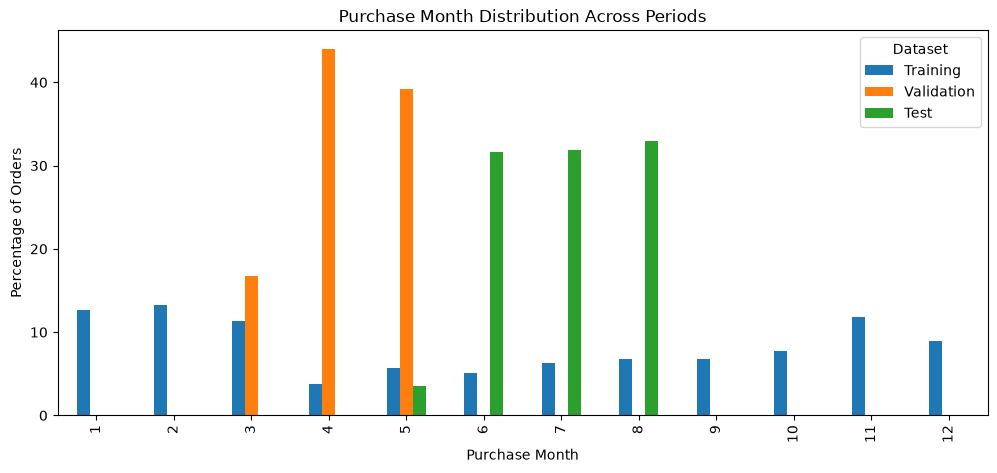

In [22]:
ax = month_distribution.mul(100).plot(
    kind="bar",
    figsize=(12, 5)
)

ax.set_title("Purchase Month Distribution Across Periods")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Percentage of Orders")
ax.legend(title="Dataset")

plt.tight_layout()
plt.show()

## 5. Target Distribution Analysis

This experiment investigates changes in the
proportion of late deliveries across temporal
partitions and purchase months.

In [ ]:
target_results = []

for name, df in periods.items():

    total_orders = len(df)
    late_orders = int(df["is_late"].sum())

    target_results.append({
        "Period": name,
        "Start_Date": df["order_purchase_timestamp"].min(),
        "End_Date": df["order_purchase_timestamp"].max(),
        "Total_Orders": total_orders,
        "Late_Orders": late_orders,
        "Late_Rate": late_orders / total_orders
    })

target_summary = pd.DataFrame(target_results)

target_summary["Late_Rate"] *= 100

target_summary_display = target_summary.copy()

target_summary_display["Late_Rate"] = (
    target_summary_display["Late_Rate"].round(3)
)

display(target_summary_display)

C:\Users\Cauan\AppData\Local\Temp\ipykernel_11772\4228483139.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(target_summary.round(3))


,Period,Start_Date,End_Date,Total_Orders,Late_Orders,Late_Rate
0,Training,2016-09-15 12:16:38,2018-03-20 09:15:24,61740,4828,7.820
1,Validation,2018-03-20 09:16:16,2018-05-26 18:16:57,15436,1032,6.686
2,Test,2018-05-26 18:18:03,2018-08-29 15:00:37,19294,674,3.493


In [20]:
monthly_target = []

for name, df in periods.items():

    summary = (
        df.groupby("purchase_month")["is_late"]
        .agg(
            total_orders="count",
            late_orders="sum",
            late_rate="mean"
        )
        .reset_index()
    )

    summary["Period"] = name
    monthly_target.append(summary)

monthly_target_df = pd.concat(
    monthly_target,
    ignore_index=True
)

monthly_target_df["late_rate"] *= 100

display(
    monthly_target_df.round(2)
)

,purchase_month,total_orders,late_orders,late_rate,Period
0,1,7819,425,5.44,Training
1,2,8208,975,11.88,Training
2,3,6969,1159,16.63,Training
3,4,2303,151,6.56,Training
4,5,3545,106,2.99,Training
5,6,3135,95,3.03,Training
6,7,3872,108,2.79,Training
7,8,4193,122,2.91,Training
8,9,4151,183,4.41,Training
9,10,4743,189,3.98,Training


NameError: name 'plt' is not defined

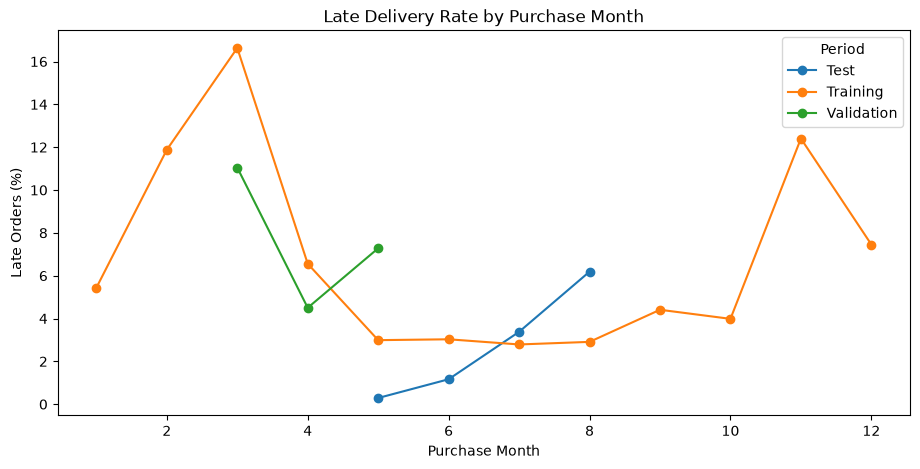

In [21]:
monthly_rates = monthly_target_df.pivot(
    index="purchase_month",
    columns="Period",
    values="late_rate"
)

ax = monthly_rates.plot(
    marker="o",
    figsize=(11, 5)
)

ax.set_title("Late Delivery Rate by Purchase Month")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Late Orders (%)")
ax.legend(title="Period")

plt.tight_layout()
plt.show()